# Dual Approach for Bermudan Option Pricing: Alfonsi's Algorithm

In the following, we discuss and implement the algorithm proposed by Alfonsi for pricing 
Bermudan options using a **pure dual approach**. The section is organized as follows:

1. We introduce the **dual representation** of the optimal stopping problem.
2. We show how this leads to a **backward minimization problem**.
3. We discuss the **strict convexification technique** and the theoretical result that 
justifies it (Theorem 1.4 in Alfonsi's article).
4. We describe the **practical framework**: the approximation space for martingale 
increments, the choice of $\phi$, and the resulting least squares problem.
5. Finally, we present the **Monte Carlo estimator** and the training/pricing split.

---

## 1. The Optimal Stopping Problem and Its Dual Representation

The classical discrete-time optimal stopping problem is:

$$
U_n = \sup_{\tau \in \mathcal{T}_{n,N}} \mathbb{E}[Z_\tau \mid \mathcal{F}_n],
$$

where $\mathcal{T}_{n,N}$ denotes the set of stopping times taking values in $\{n, \ldots, N\}$,
and $Z_\tau$ represents the discounted payoff at the stopping time $\tau$.

It can be shown that $U_n$ admits an equivalent **dual representation**:

$$
U_n = \inf_{M \in \mathbb{H}^p} \mathbb{E}\left[\max_{n \leq j \leq N} 
\{Z_j - (M_j - M_n)\} \,\bigg|\, \mathcal{F}_n \right],
$$

where the infimum is taken over all martingales $M \in \mathbb{H}^p$. Intuitively, the dual 
approach seeks the martingale that best approximates the Snell envelope from above.

---

## 2. Decomposition into a Backward Minimization Problem

Rewriting the global minimization problem in terms of **martingale increments** 
$\Delta M_{n+1} = M_{n+1} - M_n$, one obtains:

$$
U_0 = \inf_{M \in \mathbb{H}^p} \mathbb{E}\left[\max_{0 \leq j \leq N} 
\{Z_j - (M_j - M_0)\}\right]
$$

$$
= \mathbb{E}[Z_N] + \inf_{\Delta M_1 \in \mathcal{H}_1^p, \ldots, \Delta M_N \in \mathcal{H}_N^p} 
\sum_{n=0}^{N-1} \mathbb{E}\left[\left(Z_n + \Delta M_{n+1} - 
\max_{n+1 \leq j \leq N}\left\{Z_j - \sum_{i=n+2}^{j} \Delta M_i\right\}\right)_+\right].
$$

This decomposition is key: it allows us to split the global minimization into a **sequence 
of local minimization problems**, solved **backward in time** from $n = N-1$ to $n = 0$. 
At each step $n$, one minimizes over $\Delta M_{n+1} \in \mathcal{H}_{n+1}^p$:

$$
\inf_{\Delta M_{n+1} \in \mathcal{H}_{n+1}^p} \mathbb{E}\left[\left(Z_n + \Delta M_{n+1} - 
\max_{n+1 \leq j \leq N}\left\{Z_j - \sum_{i=n+2}^{j} \Delta M_i\right\}\right)_+\right],
$$

treating the future increments $\Delta M_{i}$ for $i \geq n+2$ as already determined from 
previous backward steps.

---

## 3. Strict Convexification

A key difficulty is that the positive part function $x \mapsto x_+$ is **convex but not 
strictly convex**, which leads to a **non-uniqueness issue** for the minimizer.

To overcome this, one replaces $x_+$ with a **strictly convex function** $\phi$. This is 
justified by **Theorem 1.4** in Alfonsi's article, which guarantees that if $\phi$ is 
strictly convex, then:

- the minimizer is **unique**,
- it coincides with the martingale appearing in the **Doob–Meyer decomposition** of $U_n$.

Hence the strict convexification does not alter the solution, but restores uniqueness and 
makes the problem tractable.

---

## 4. Practical Framework

### 4.1 Approximation Space for Martingale Increments

We approximate the space of martingale increments via **linear combinations** of basis 
elements of the form:

$$
X^{p,k}_{t_{i,j}} - X^{p,k}_{t_{i,j-1}} = u^p_{i,j-1}(S_{t_{i,j-1}})
\left(\mathcal{A}^k_{t_{i,j}} - \mathcal{A}^k_{t_{i,j-1}}\right),
$$

where:
- the index $i = 1, \ldots, N$ labels the **exercise dates** of the Bermudan option,
- the index $j = 1, \ldots, \bar{N}$ subdivides each interval $[t_{i-1}, t_i]$ into 
$\bar{N}$ **sub-intervals**,
- $u^p_{i,j-1}(S_{t_{i,j-1}})$ is a family of functions mapping the asset space to 
$\mathbb{R}$, evaluated at the previous sub-interval date,
- $\mathcal{A}^k$ are discounted asset processes whose increments provide the martingale 
structure.

The martingale increment over the $i$-th exercise period is then:

$$
\Delta M_{i+1} = \sum_{j=1}^{\bar{N}} \sum_{p,k} \alpha^{p,k}_{i,j} 
\left(X^{p,k}_{t_{i,j}} - X^{p,k}_{t_{i,j-1}}\right),
$$

where the coefficients $\alpha^{p,k}_{i,j} \in \mathbb{R}$ are the **parameters to optimize**.

### 4.2 Choice of $\phi$ and Least Squares Reduction

We choose $\phi(x) = x^2$, which is strictly convex. Under this choice, the backward 
minimization problem at each stage reduces to a **classical least squares problem**, 
solvable via standard linear algebra techniques.

---

## 5. Monte Carlo Estimator and Training/Pricing Split

Once the optimal coefficients $\{\alpha^{p,k}_{i,j}\}$ have been computed, the price 
estimator is:

$$
\hat{U}_0^Q = \frac{1}{Q} \sum_{q=1}^{Q} \max_{0 \leq j \leq N} 
\left\{ \hat{Z}_j^q - \sum_{i=1}^{j} \alpha_i^Q \cdot \Delta \hat{X}_i^q \right\}.
$$

As in the **Longstaff–Schwartz algorithm**, to avoid **overfitting** (since the 
coefficients $\alpha$ are estimated on the same paths used for pricing), we split 
the simulation into two independent phases:

- **Training phase**: simulate a first set of paths and solve the backward least squares 
problems to compute the optimal coefficients $\alpha^Q$.
- **Pricing phase**: simulate a fresh, independent set of paths and use the estimated 
coefficients to evaluate the Monte Carlo estimator $\hat{U}_0^Q$.

This separation ensures that the estimator remains unbiased and avoids the lookahead bias 
that would arise from using the same paths for both calibration and pricing.

In [1]:
from code_utils import *

In [2]:
# Parameters
N = 50    		# Number of exercising dates
N_bar = 5     	# Number of intervals between two exercising dates
K = 100   		# Strike price
r = 0.05  		# Risk-free rate
sigma = 0.3   	# Volatility
T = 0.2   		# Maturity

seed = 42    	# Seed for reproducibility

paths = 10**5 	# Number of Monte Carlo paths
pricing_paths = 10**5
P = 20			# Number of elements in the local basis 

real_prices = np.array([
    40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000,
    35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
    30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000,
    25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
    20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366,
    15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
    11.06257234, 10.30856320,  9.58471980,  8.89180771,  8.23041673,
     7.60094690,  7.00361025,  6.43844700,  5.90532237,  5.40390521,
     4.93370425,  4.49410547,  4.08432251,  3.70344748,  3.35050142,
     3.02435964,  2.72386986,  2.44779995,  2.19486933,  1.96380311,
     1.75326609,  1.56197956,  1.38862261,  1.23195119,  1.09070376,
     0.96370545,  0.84978944,  0.74786820,  0.65689777,  0.57588855,
     0.50392803,  0.44013960,  0.38373063,  0.33395543,  0.29012326,
     0.25161274,  0.21784490,  0.18829301,  0.16248633,  0.13999277,
     0.12042199,  0.10342780,  0.08869869,  0.07595400,  0.06494518,
     0.05545341,  0.04728321,  0.04026147,  0.03423616,  0.02907429,
     0.02465918
])

prices = np.empty(81)
uncertainty = np.empty(81)
percentage_errors = np.empty(81)
coefficients = {}

for S0 in range(60, 141):

    # Temporal grid
    exercise_time = np.linspace(0, T, N + 1)
    exercise_indices = range(0, N_bar * N + 1, N_bar)
    dense_grid = np.linspace(0, T, N_bar * N + 1)

    discount_factor = np.exp(-r * dense_grid)
    discount_factor_exercise_time = np.exp(-r * exercise_time)

    # Training paths 
    asset = S0 * simulate_gbm_nv(r, sigma, T, dense_grid[1] - dense_grid[0], paths, seed)
    discounted_asset = asset * discount_factor[:, np.newaxis]
    discounted_payoff = (np.maximum(K - asset[exercise_indices, :], 0) * discount_factor_exercise_time[:, np.newaxis])

    # Pricing paths 
    asset_pricing = S0 * simulate_gbm_nv(r, sigma, T, dense_grid[1] - dense_grid[0], pricing_paths, seed + 1)
    discounted_asset_pricing = asset_pricing * discount_factor[:, np.newaxis]
    discounted_payoff_pricing = (np.maximum(K - asset_pricing[exercise_indices, :], 0) * discount_factor_exercise_time[:, np.newaxis])

    prices[S0 - 60], _ , uncertainty[S0 - 60], coefficients[S0] = upper_bound_alfonsi_indicator_mod( asset, asset_pricing, discounted_asset, discounted_asset_pricing, discounted_payoff, discounted_payoff_pricing, paths, pricing_paths, N, N_bar, P )
    percentage_errors[S0- 60] = np.abs(prices[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
    print(f"S0= {S0}, Estimated Price: {prices[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_errors[S0-60]:.2f}%, Uncertainty: {uncertainty[S0-60]:.5f}")

S0= 60, Estimated Price: 40.01083, Real Price: 40.00000, Percentage Error: 0.03%, Uncertainty: 0.00009
S0= 61, Estimated Price: 39.01145, Real Price: 39.00000, Percentage Error: 0.03%, Uncertainty: 0.00011
S0= 62, Estimated Price: 38.01222, Real Price: 38.00000, Percentage Error: 0.03%, Uncertainty: 0.00015
S0= 63, Estimated Price: 37.01311, Real Price: 37.00000, Percentage Error: 0.04%, Uncertainty: 0.00020
S0= 64, Estimated Price: 36.01428, Real Price: 36.00000, Percentage Error: 0.04%, Uncertainty: 0.00027
S0= 65, Estimated Price: 35.01577, Real Price: 35.00000, Percentage Error: 0.05%, Uncertainty: 0.00035
S0= 66, Estimated Price: 34.01767, Real Price: 34.00000, Percentage Error: 0.05%, Uncertainty: 0.00043
S0= 67, Estimated Price: 33.01995, Real Price: 33.00000, Percentage Error: 0.06%, Uncertainty: 0.00053
S0= 68, Estimated Price: 32.02262, Real Price: 32.00000, Percentage Error: 0.07%, Uncertainty: 0.00063
S0= 69, Estimated Price: 31.02577, Real Price: 31.00000, Percentage Error

One thing I want to underline is that after having tuned the algorithm ATM the results deep OTM are worse!

In [3]:
np.savez('alfonsi_results.npz', S0=np.arange(60,141), price=prices, error=percentage_errors, uncertainty=uncertainty)

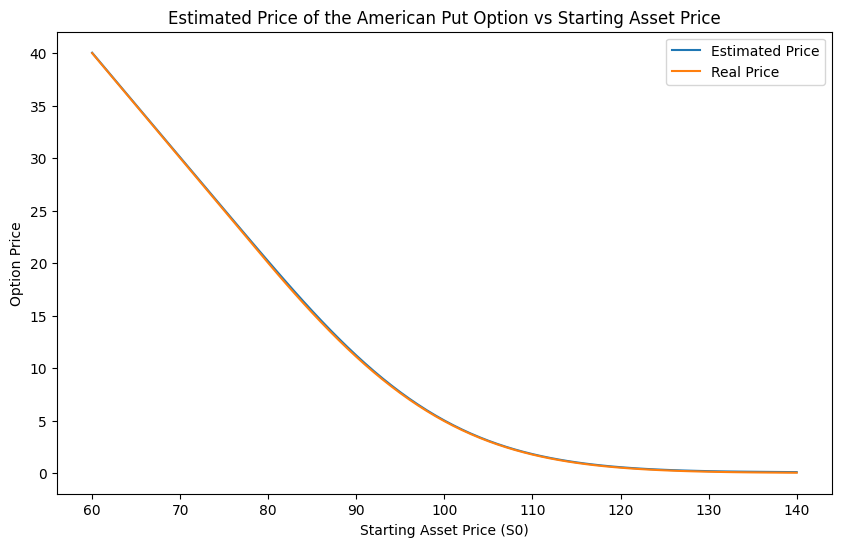

In [4]:
# Plot of the price of the option wrt the starting value of the asset
plt.figure(figsize = (10,6))
plt.plot(np.arange(60,141), prices, label='Estimated Price')
plt.plot(np.arange(60,141), real_prices, label='Real Price')
plt.title('Estimated Price of the American Put Option vs Starting Asset Price')
plt.xlabel('Starting Asset Price (S0)')
plt.ylabel('Option Price')
plt.legend()

In [5]:
def upper_bound_american_put_alfonsi(K, S0, T, N, r, sigma, seed, npaths_train, npaths_pricing, N_bar, P):

    # Temporal grid
    exercise_time = np.linspace(0, T, N + 1)
    exercise_indices = range(0, N_bar * N + 1, N_bar)
    dense_grid = np.linspace(0, T, N_bar * N + 1)

    discount_factor = np.exp(-r * dense_grid)
    discount_factor_exercise_time = np.exp(-r * exercise_time)

    # Training paths 
    asset = S0 * simulate_gbm_nv(r, sigma, T, dense_grid[1] - dense_grid[0], npaths_train, seed)
    discounted_asset = asset * discount_factor[:, np.newaxis]
    discounted_payoff = (np.maximum(K - asset[exercise_indices, :], 0) * discount_factor_exercise_time[:, np.newaxis])

    # Pricing paths 
    asset_pricing = S0 * simulate_gbm_nv(r, sigma, T, dense_grid[1] - dense_grid[0], npaths_pricing, seed + 1)
    discounted_asset_pricing = asset_pricing * discount_factor[:, np.newaxis]
    discounted_payoff_pricing = (np.maximum(K - asset_pricing[exercise_indices, :], 0) * discount_factor_exercise_time[:, np.newaxis])
    
    price_estimate, _ , uncertainty_estimate, _ = upper_bound_alfonsi_indicator_mod( asset, asset_pricing, discounted_asset, discounted_asset_pricing, discounted_payoff, discounted_payoff_pricing, npaths_train, npaths_pricing, N, N_bar, P )
    return price_estimate , uncertainty_estimate

In [6]:
N = 50    		# Number of exercising dates
N_bar = 5     	# Number of intervals between two exercising dates
K = 100   		# Strike price
r = 0.05  		# Risk-free rate
sigma = 0.3   	# Volatility
T = 0.2   		# Maturity

seed = 42    	# Seed for reproducibility

npaths_train = 10**5 	# Number of Monte Carlo paths for training
npaths_pricing = 10**5 	# Number of Monte Carlo paths for pricing
P = 50			# Number of elements in the local basis 


real_prices = np.array([
    40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000,
    35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
    30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000,
    25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
    20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366,
    15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
    11.06257234, 10.30856320,  9.58471980,  8.89180771,  8.23041673,
     7.60094690,  7.00361025,  6.43844700,  5.90532237,  5.40390521,
     4.93370425,  4.49410547,  4.08432251,  3.70344748,  3.35050142,
     3.02435964,  2.72386986,  2.44779995,  2.19486933,  1.96380311,
     1.75326609,  1.56197956,  1.38862261,  1.23195119,  1.09070376,
     0.96370545,  0.84978944,  0.74786820,  0.65689777,  0.57588855,
     0.50392803,  0.44013960,  0.38373063,  0.33395543,  0.29012326,
     0.25161274,  0.21784490,  0.18829301,  0.16248633,  0.13999277,
     0.12042199,  0.10342780,  0.08869869,  0.07595400,  0.06494518,
     0.05545341,  0.04728321,  0.04026147,  0.03423616,  0.02907429,
     0.02465918
])

for S0 in range(60, 141):
    price, unc = upper_bound_american_put_alfonsi(K, S0, T, N, r, sigma, seed, npaths_train, npaths_pricing, N_bar, P)
    pct_err = np.abs(price - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
    print(f"S0={S0}, Estimated Price: {price:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {pct_err:.2f}%, Uncertainty: {unc:.5f}")

S0=60, Estimated Price: 40.03936, Real Price: 40.00000, Percentage Error: 0.10%, Uncertainty: 0.00021
S0=61, Estimated Price: 39.04114, Real Price: 39.00000, Percentage Error: 0.11%, Uncertainty: 0.00023
S0=62, Estimated Price: 38.04310, Real Price: 38.00000, Percentage Error: 0.11%, Uncertainty: 0.00025
S0=63, Estimated Price: 37.04520, Real Price: 37.00000, Percentage Error: 0.12%, Uncertainty: 0.00028
S0=64, Estimated Price: 36.04750, Real Price: 36.00000, Percentage Error: 0.13%, Uncertainty: 0.00033
S0=65, Estimated Price: 35.05010, Real Price: 35.00000, Percentage Error: 0.14%, Uncertainty: 0.00038
S0=66, Estimated Price: 34.05302, Real Price: 34.00000, Percentage Error: 0.16%, Uncertainty: 0.00043
S0=67, Estimated Price: 33.05623, Real Price: 33.00000, Percentage Error: 0.17%, Uncertainty: 0.00049
S0=68, Estimated Price: 32.05977, Real Price: 32.00000, Percentage Error: 0.19%, Uncertainty: 0.00054
S0=69, Estimated Price: 31.06369, Real Price: 31.00000, Percentage Error: 0.21%, U